# Visualisation Suite — NetworkX

Seven visualisations, all built on **NetworkX**. Three are interactive HTML you can open in a
browser and drag around; one is an animated cascade.

| # | Output | Type |
|---|---|---|
| 1 | Interactive network explorer | HTML, draggable |
| 2 | Interactive sensor map | HTML, draggable |
| 3 | **Animated information cascade** | GIF |
| 4 | Interactive results dashboard | HTML, hover |
| 5 | Community structure panel | PNG |
| 6 | Ego network of the top influencer | PNG |
| 7 | Degree + k-core structure | PNG |

**Install once:**
```
pip install pyvis plotly
```

Interactive files are standalone HTML - double-click to open, no server needed. Bring a laptop
to the presentation and let your faculty drag the nodes around.

In [1]:
!pip -q install pyvis plotly

import pandas as pd, numpy as np, networkx as nx, random, json, time, os
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path
Path("figures").mkdir(exist_ok=True); Path("interactive").mkdir(exist_ok=True)
plt.rcParams.update({"savefig.dpi":300,"font.size":10})
SEED=42; random.seed(SEED); np.random.seed(SEED)

edges=pd.read_csv("data/gephi_edges.csv")
G=nx.DiGraph()
for r in edges.itertuples(index=False):
    G.add_edge(r.Source,r.Target,weight=int(r.Weight))
U=G.to_undirected(); deg=dict(G.degree())
try:
    lab=pd.read_csv("data/gephi_nodes.csv"); LAB=dict(zip(lab.Id,lab.Label))
except Exception: LAB={}
print(f"{G.number_of_nodes():,} nodes / {G.number_of_edges():,} edges")

# communities
try:
    m=pd.read_csv("data/gephi_node_metrics.csv")
    idc="Id" if "Id" in m.columns else m.columns[0]
    mc=[x for x in m.columns if "odularity" in x.lower().replace(" ","")][0]
    COMM=dict(zip(m[idc],m[mc]))
except Exception:
    cs=nx.community.louvain_communities(U,weight="weight",seed=SEED)
    COMM={v:i for i,g in enumerate(cs) for v in g}
NC=len(set(COMM.values())); print(f"{NC} communities")
PALETTE=["#e6194b","#3cb44b","#4363d8","#f58231","#911eb4","#42d4f4",
         "#f032e6","#bfef45","#fabed4","#469990","#dcbeff","#9A6324"]
def ccol(n): return PALETTE[COMM.get(n,0)%len(PALETTE)]

6,434 nodes / 259,122 edges
8 communities


## 1 — Interactive network explorer

A browser-based network you can **drag, zoom and hover**. The full graph (259k edges) would
freeze any browser, so we show the high-degree core. Hovering a node reports its degree,
community and rank.

In [2]:
from pyvis.network import Network

THRESH=350
core=[n for n in G if deg[n]>=THRESH]
sub=G.subgraph(core).copy()
print(f"interactive subgraph: {sub.number_of_nodes()} nodes / {sub.number_of_edges():,} edges")

rank={n:i+1 for i,n in enumerate(sorted(G.nodes(),key=lambda x:-deg[x]))}
net=Network(height="820px",width="100%",bgcolor="#0e1117",font_color="#e8eaed",
            directed=True,notebook=False,cdn_resources="in_line")
net.barnes_hut(gravity=-9000,central_gravity=0.25,spring_length=130,spring_strength=0.02)
mx=max(deg.values())
for n in sub.nodes():
    net.add_node(n, label=LAB.get(n,n[:8]),
                 size=8+34*(deg[n]/mx)**0.55, color=ccol(n),
                 title=(f"{LAB.get(n,n[:8])}\n"
                        f"degree: {deg[n]}  (rank #{rank[n]} of {G.number_of_nodes():,})\n"
                        f"in: {G.in_degree(n)}   out: {G.out_degree(n)}\n"
                        f"community: {COMM.get(n,'?')}"))
for u,v,d in sub.edges(data=True):
    net.add_edge(u,v,value=d["weight"],color="#2f3846")
net.write_html("interactive/1_network_explorer.html",open_browser=False,notebook=False)
print("saved interactive/1_network_explorer.html  <- double-click to open")

interactive subgraph: 171 nodes / 6,324 edges
saved interactive/1_network_explorer.html  <- double-click to open


## 2 — Interactive sensor map

The same network with the CELF-selected monitoring sensors in red. Hovering a sensor shows its
rank. This is the figure that shows **data, method and result in one frame**.

In [3]:
sensors=[]
try:
    h2u=json.load(open("username_mapping_v3_PRIVATE.json")); u2h={v:k for k,v in h2u.items()}
    su=[r for r in pd.read_csv("data/sensors.csv")["sensor"]]
    sensors=[u2h[u] for u in su if u in u2h]
    print(f"{len(sensors)} sensors loaded")
except Exception as e:
    print("sensors.csv not found - run section3a first")

if sensors:
    S=set(sensors); srank={n:i+1 for i,n in enumerate(sensors)}
    show=sorted(set(core)|S)
    sub2=G.subgraph(show).copy()
    net=Network(height="820px",width="100%",bgcolor="#0e1117",font_color="#e8eaed",
                directed=True,notebook=False,cdn_resources="in_line")
    net.barnes_hut(gravity=-9000,central_gravity=0.25,spring_length=140)
    for n in sub2.nodes():
        is_s = n in S
        net.add_node(n, label=LAB.get(n,n[:8]) if is_s else "",
                     size=(26+22*(deg[n]/mx)**0.5) if is_s else 6+12*(deg[n]/mx)**0.5,
                     color="#ff3b30" if is_s else "#39414f",
                     borderWidth=3 if is_s else 0,
                     title=(f"SENSOR #{srank[n]}\n{LAB.get(n,n[:8])}\ndegree {deg[n]}"
                            if is_s else f"{LAB.get(n,n[:8])}\ndegree {deg[n]}"))
    for u,v,d in sub2.edges(data=True):
        hot = u in S or v in S
        net.add_edge(u,v,color="#8c2f2a" if hot else "#232a35",value=d["weight"])
    net.write_html("interactive/2_sensor_map.html",open_browser=False,notebook=False)
    print("saved interactive/2_sensor_map.html")

20 sensors loaded
saved interactive/2_sensor_map.html


## 3 — Animated information cascade

Watch information actually spread. Red = just activated, fading through orange and yellow to
green for earlier adopters. Edges are drawn once as a static layer so the animation renders in
about a second rather than timing out.

In [4]:
random.seed(7)
asub=G.subgraph([n for n in G if deg[n]>=350]).copy()
N=list(asub.nodes()); idx={n:i for i,n in enumerate(N)}
P={}
for u,v in asub.edges():
    d=asub.in_degree(v); P[(u,v)]=min(1.0/d,0.5) if d>0 else 0.5

seed_node=max(asub.nodes(),key=lambda n:asub.out_degree(n))
active={seed_node}; frontier=[seed_node]; waves=[{seed_node}]
while frontier and len(waves)<8:
    nxt=[]
    for u in frontier:
        for v in asub.successors(u):
            if v not in active and random.random()<P[(u,v)]*2.0:
                active.add(v); nxt.append(v)
    if nxt: waves.append(set(nxt))
    frontier=nxt
print("wave sizes:",[len(w) for w in waves],"| total reached",len(active))

pos=nx.spring_layout(asub,k=0.5,iterations=50,seed=SEED)
xy=np.array([pos[n] for n in N]); segs=[[pos[u],pos[v]] for u,v in asub.edges()]

fig,ax=plt.subplots(figsize=(9,9),facecolor="#0e1117")
ax.set_facecolor("#0e1117"); ax.axis("off")
ax.add_collection(LineCollection(segs,colors="#4a5464",linewidths=0.25,alpha=0.10))
scat=ax.scatter(xy[:,0],xy[:,1],s=26,c=["#2b3240"]*len(N),linewidths=0,zorder=3)
ax.set_xlim(xy[:,0].min()*1.08,xy[:,0].max()*1.08); ax.set_ylim(xy[:,1].min()*1.08,xy[:,1].max()*1.08)
title=ax.set_title("",color="#e8eaed",fontsize=13,pad=12)
PAL=["#ff3b30","#ff8c42","#ffc145","#9be36d","#4dd4ac"]
def draw(i):
    col=np.array(["#2b3240"]*len(N),dtype=object); sz=np.full(len(N),26.0)
    for j in range(i+1):
        cc=PAL[min(i-j,4)]
        for n in waves[j]:
            col[idx[n]]=cc; sz[idx[n]]=170 if i==j else 60
    scat.set_color(list(col)); scat.set_sizes(sz)
    on=sum(len(w) for w in waves[:i+1])
    title.set_text(f"Information cascade — step {i}   |   {on} of {len(N)} users reached ({100*on/len(N):.0f}%)")
    return scat,title
FuncAnimation(fig,draw,frames=len(waves),interval=850).save(
    "figures/3_cascade_animation.gif",writer=PillowWriter(fps=1.2),dpi=72,
    savefig_kwargs={"facecolor":"#0e1117"})
plt.close()
print("saved figures/3_cascade_animation.gif")

wave sizes: [1, 8, 18, 35, 43, 24, 7, 2] | total reached 138
saved figures/3_cascade_animation.gif


## 4 — Interactive results dashboard

Four linked Plotly charts with hover tooltips: influence spread, detection rate, redundancy and
precision. Opens in a browser.

In [5]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig=make_subplots(rows=2,cols=2,subplot_titles=(
    "Influence spread by algorithm","Early detection rate",
    "Redundancy in the degree heuristic","Alert precision"))

try:
    im=pd.read_csv("im_results.csv").pivot_table(index="k",columns="algorithm",values="spread")
    for a in im.columns:
        fig.add_trace(go.Scatter(x=im.index,y=im[a],name=a,mode="lines+markers",
            line=dict(width=4 if a=="CELF" else 2)),row=1,col=1)
except Exception: pass
try:
    d=pd.read_csv("data/detection_results.csv")
    for a in d.algorithm.unique():
        s=d[d.algorithm==a].sort_values("k")
        fig.add_trace(go.Scatter(x=s.k,y=100*s.detection_rate,name=a,mode="lines+markers",
            line=dict(width=4 if "CELF" in a else 2),showlegend=False),row=1,col=2)
        if a=="CELF-detect":
            fig.add_trace(go.Scatter(x=s.k,y=s.precision,name="precision",mode="lines+markers",
                line=dict(width=3,color="#8e44ad"),showlegend=False),row=2,col=2)
except Exception: pass
try:
    r=pd.read_csv("figures/blockE_redundancy.csv")
    fig.add_trace(go.Bar(x=r.k,y=r.sum_individual,name="sum of individual",
        marker_color="#95a5a6",showlegend=False),row=2,col=1)
    fig.add_trace(go.Bar(x=r.k,y=r.joint_spread,name="actual joint",
        marker_color="#c0392b",showlegend=False),row=2,col=1)
except Exception: pass

fig.update_xaxes(title_text="seed set size k",row=1,col=1)
fig.update_xaxes(title_text="number of sensors k",row=1,col=2)
fig.update_xaxes(title_text="k",row=2,col=1); fig.update_xaxes(title_text="sensors k",row=2,col=2)
fig.update_yaxes(title_text="spread",row=1,col=1); fig.update_yaxes(title_text="% detected",row=1,col=2)
fig.update_yaxes(title_text="spread",row=2,col=1); fig.update_yaxes(title_text="precision",row=2,col=2)
fig.update_layout(height=820,template="plotly_white",
    title_text="Influence Maximization & Early Detection — Results Dashboard",
    hovermode="x unified")
fig.write_html("interactive/4_results_dashboard.html")
print("saved interactive/4_results_dashboard.html")

saved interactive/4_results_dashboard.html


## 5 — Community structure panel

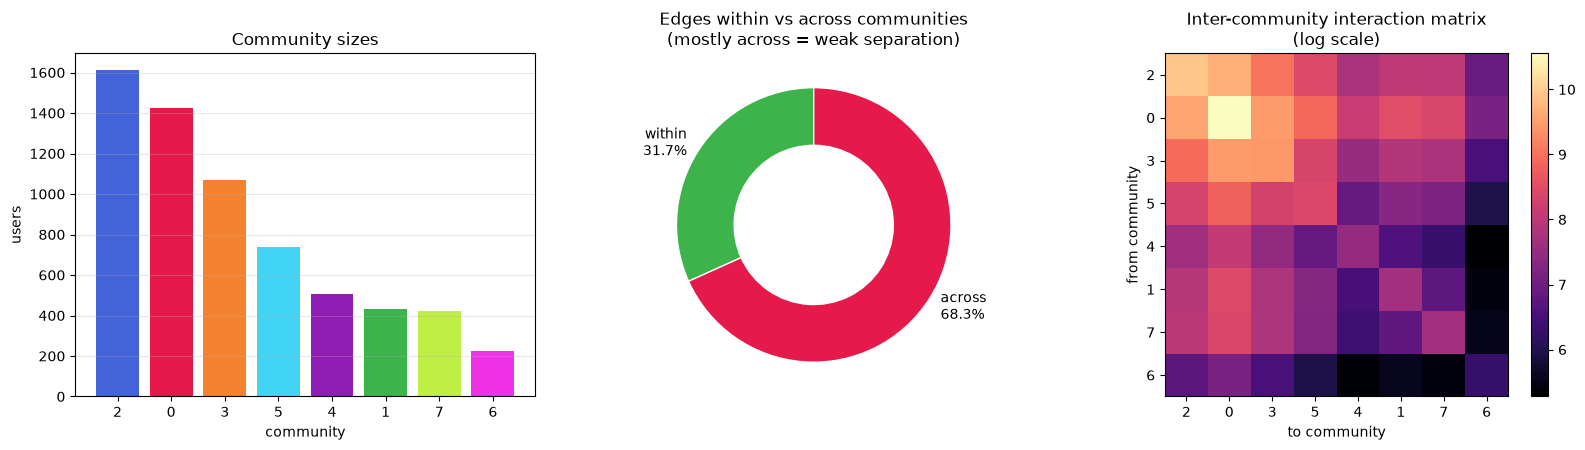

saved figures/5_community_panel.png


In [6]:
from collections import Counter
sizes=Counter(COMM.values())
big=[c_ for c_,s in sizes.most_common() if s>=20]
intra=sum(1 for u,v in G.edges() if COMM.get(u)==COMM.get(v))
inter=G.number_of_edges()-intra

fig,ax=plt.subplots(1,3,figsize=(16,4.6))
ids=[c_ for c_,_ in sizes.most_common()]
ax[0].bar(range(len(ids)),[sizes[c_] for c_ in ids],
          color=[PALETTE[c_%len(PALETTE)] for c_ in ids])
ax[0].set_xticks(range(len(ids))); ax[0].set_xticklabels(ids)
ax[0].set_xlabel("community"); ax[0].set_ylabel("users")
ax[0].set_title("Community sizes"); ax[0].grid(alpha=.3,axis="y")

ax[1].pie([intra,inter],labels=[f"within\n{100*intra/G.number_of_edges():.1f}%",
                                f"across\n{100*inter/G.number_of_edges():.1f}%"],
          colors=["#3cb44b","#e6194b"],autopct="",startangle=90,
          wedgeprops=dict(width=0.42,edgecolor="white"))
ax[1].set_title("Edges within vs across communities\n(mostly across = weak separation)")

M=np.zeros((len(big),len(big)))
pos_i={c_:i for i,c_ in enumerate(big)}
for u,v in G.edges():
    a,b=COMM.get(u),COMM.get(v)
    if a in pos_i and b in pos_i: M[pos_i[a],pos_i[b]]+=1
im_=ax[2].imshow(np.log1p(M),cmap="magma")
ax[2].set_xticks(range(len(big))); ax[2].set_xticklabels(big)
ax[2].set_yticks(range(len(big))); ax[2].set_yticklabels(big)
ax[2].set_xlabel("to community"); ax[2].set_ylabel("from community")
ax[2].set_title("Inter-community interaction matrix\n(log scale)")
plt.colorbar(im_,ax=ax[2],fraction=0.046)
plt.tight_layout(); plt.savefig("figures/5_community_panel.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/5_community_panel.png")

## 6 — Ego network of the top influencer

Zooms in on the single most connected user and everyone they interact with. Makes the hub
structure concrete rather than abstract.

ego network of user_00001: 161 nodes / 5743 edges


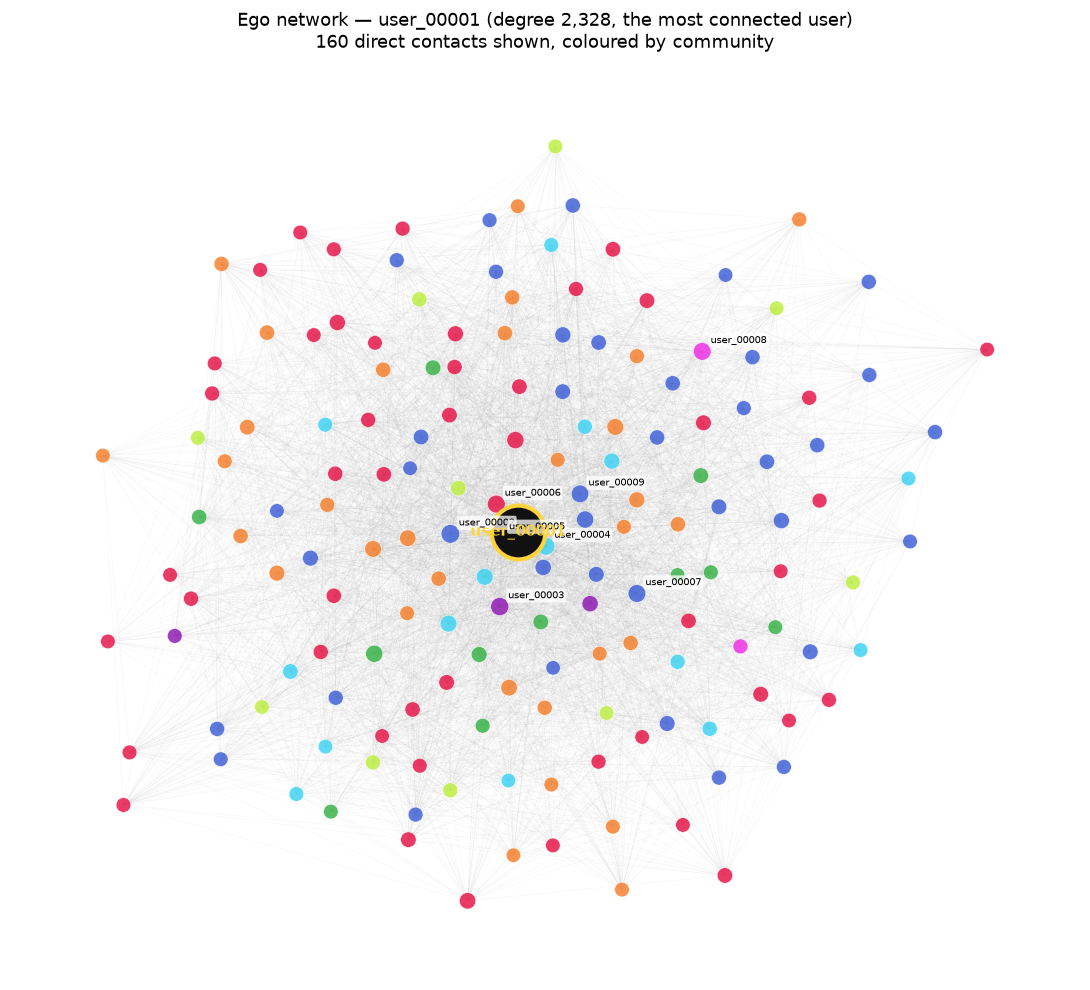

saved figures/6_ego_network.png


In [7]:
hub=max(G.nodes(),key=lambda n:deg[n])
nbrs=list(set(G.successors(hub))|set(G.predecessors(hub)))
if len(nbrs)>160:
    nbrs=sorted(nbrs,key=lambda n:-deg[n])[:160]
ego=G.subgraph([hub]+nbrs).copy()
print(f"ego network of {LAB.get(hub,hub[:8])}: {ego.number_of_nodes()} nodes / {ego.number_of_edges()} edges")

pos_e=nx.spring_layout(ego,k=0.9,iterations=80,seed=SEED)
pos_e[hub]=np.array([0,0])
fig,ax=plt.subplots(figsize=(11,10))
nx.draw_networkx_edges(ego.to_undirected(),pos_e,ax=ax,alpha=0.07,width=0.35,
                       edge_color="#888",arrows=False)
others=[n for n in ego if n!=hub]
nx.draw_networkx_nodes(ego,pos_e,ax=ax,nodelist=others,
                       node_color=[ccol(n) for n in others],
                       node_size=[40+260*(deg[n]/mx)**0.7 for n in others],
                       alpha=0.85,linewidths=0.4,edgecolors="white")
nx.draw_networkx_nodes(ego,pos_e,ax=ax,nodelist=[hub],node_color="#111",
                       node_size=1500,edgecolors="#ffd43b",linewidths=3)
top=sorted(others,key=lambda n:-deg[n])[:8]
for n in top:
    ax.annotate(LAB.get(n,n[:8]),pos_e[n],fontsize=7.5,
                xytext=(6,6),textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.18",fc="white",ec="none",alpha=0.75))
nx.draw_networkx_labels(ego,pos_e,ax=ax,font_size=11,font_weight="bold",font_color="#ffd43b",
                        labels={hub:LAB.get(hub,hub[:8])})
ax.set_title(f"Ego network — {LAB.get(hub,hub[:8])} (degree {deg[hub]:,}, the most connected user)\n"
             f"{len(nbrs)} direct contacts shown, coloured by community",fontsize=13,pad=14)
ax.axis("off")
plt.tight_layout(); plt.savefig("figures/6_ego_network.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/6_ego_network.png")

## 7 — Degree and k-core structure

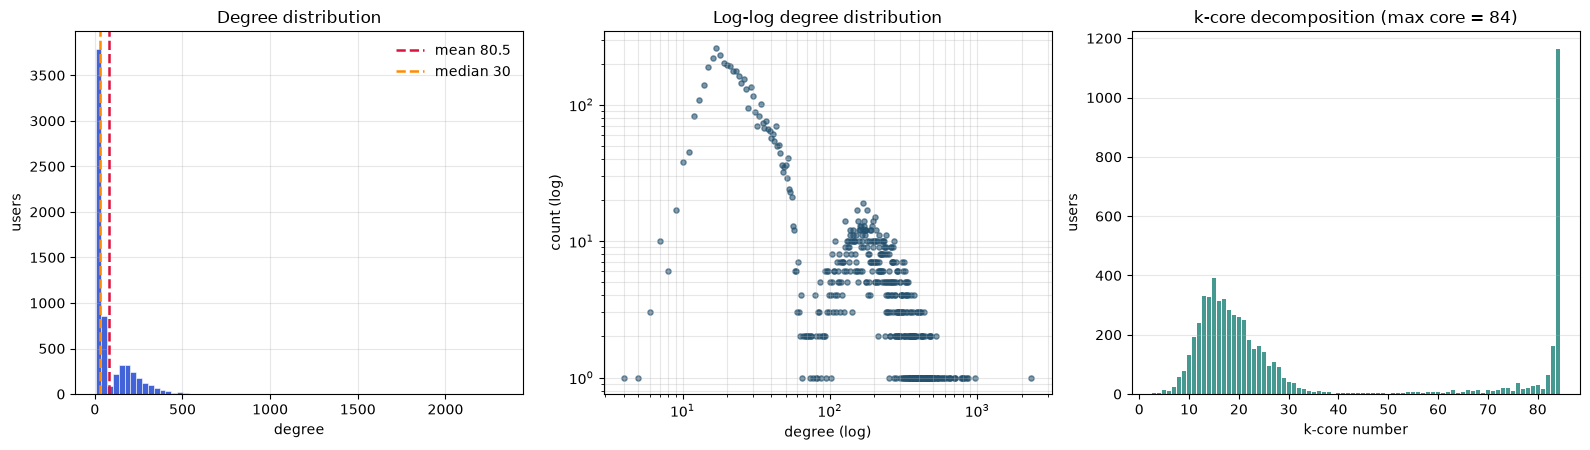

saved figures/7_degree_kcore.png

=== ALL OUTPUTS ===
  OK      interactive/1_network_explorer.html
  OK      interactive/2_sensor_map.html
  OK      figures/3_cascade_animation.gif
  OK      interactive/4_results_dashboard.html
  OK      figures/5_community_panel.png
  OK      figures/6_ego_network.png
  OK      figures/7_degree_kcore.png


In [8]:
core_no=nx.core_number(U)
degs=np.array([deg[n] for n in G])
fig,ax=plt.subplots(1,3,figsize=(16,4.6))

ax[0].hist(degs,bins=70,color="#4363d8",edgecolor="white",linewidth=.4)
ax[0].axvline(degs.mean(),color="crimson",ls="--",lw=1.8,label=f"mean {degs.mean():.1f}")
ax[0].axvline(np.median(degs),color="darkorange",ls="--",lw=1.8,label=f"median {np.median(degs):.0f}")
ax[0].set_xlabel("degree"); ax[0].set_ylabel("users"); ax[0].set_title("Degree distribution")
ax[0].legend(frameon=False); ax[0].grid(alpha=.3)

from collections import Counter as C2
cnt=C2(degs); ks=np.array(sorted(cnt)); fs=np.array([cnt[k] for k in ks])
ax[1].scatter(ks,fs,s=14,alpha=.6,color="#22506e")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("degree (log)"); ax[1].set_ylabel("count (log)")
ax[1].set_title("Log-log degree distribution"); ax[1].grid(alpha=.3,which="both")

kc=C2(core_no.values()); xs=sorted(kc)
ax[2].bar(xs,[kc[k] for k in xs],color="#469990")
ax[2].set_xlabel("k-core number"); ax[2].set_ylabel("users")
ax[2].set_title(f"k-core decomposition (max core = {max(core_no.values())})")
ax[2].grid(alpha=.3,axis="y")
plt.tight_layout(); plt.savefig("figures/7_degree_kcore.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/7_degree_kcore.png")

print("\n=== ALL OUTPUTS ===")
for f in ["interactive/1_network_explorer.html","interactive/2_sensor_map.html",
          "figures/3_cascade_animation.gif","interactive/4_results_dashboard.html",
          "figures/5_community_panel.png","figures/6_ego_network.png",
          "figures/7_degree_kcore.png"]:
    print(("  OK      " if os.path.exists(f) else "  MISSING ")+f)

## Presenting these

**Open the three HTML files in a browser and drag the nodes.** That is the moment that lands -
a static PNG looks like homework, a network you can manipulate looks like a tool.

Suggested order:
1. **Cascade animation** - shows the problem (information spreading)
2. **Interactive explorer** - shows the data (let her drag it)
3. **Sensor map** - shows the result (where we place monitors)
4. **Dashboard** - shows the numbers

Everything is built with **NetworkX** for graph construction and analysis; PyVis and Plotly only
render what NetworkX computes.